# 03 — Cellular & Single-Nucleus Trajectory Mapping Across Root and Shoot Lineages (WP3)

**Objective:** Map the TabPFN-identified barosensory ($P_{\text{total}}$) and hypoxia ($p\text{O}_2$) molecular hubs onto **(1)** 99 measured cell-population TRAP-seq and total RNA microarrays across 19 cell-type promoters (`GSE14493`, `GSE14502`; Mustroph et al., *PNAS* 2009) $\pm$ exogenous sucrose rescue, and **(2)** 40,860 QC-filtered root-tip nuclei from the 2025 single-nucleus hypoxia atlas (`GSE308672`, 5-day Col-0 root tips under 21% vs 4% $\text{O}_2$).

## 1. Pathway Localization & Translatome Induction Across Cell-Type TRAP Promoters and Sucrose Rescue (`GSE14493` & `GSE14502`)

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display

PROJECT_DIR = Path("/Users/drb_laptop/Documents/Exploration_atmosphere_Biomni_lab_downloads_20261016_234156/arabidopsis_exploration_atmosphere")
s4a = pd.read_csv(PROJECT_DIR / "manuscript/tables/Table_S4A_Pathway_CellType_TRAP_and_SingleNucleus_Atlas.csv", index_col=0)
cols_trap = [
    "GSE14493_Hypoxia_NoSucrose_dlog2",
    "GSE14493_Sucrose_Rescue_vs_NoSucrose_dlog2",
    "BaselineLoc_pcer5_Shoot Epidermis",
    "BaselineLoc_prbcs_Photosynthetic Mesophyll",
    "BaselineLoc_pscr_Endodermis / QC",
    "BaselineLoc_psuc2_Phloem Companion Cells",
]
print(s4a[cols_trap].round(3).to_string())

GSE14493_Hypoxia_NoSucrose_dlog2  GSE14493_Sucrose_Rescue_vs_NoSucrose_dlog2  BaselineLoc_pcer5_Shoot Epidermis  BaselineLoc_prbcs_Photosynthetic Mesophyll  BaselineLoc_pscr_Endodermis / QC  BaselineLoc_psuc2_Phloem Companion Cells
Pathway                                                                                                                                                                                                                                                                          
ERF_VII_Core_Hypoxia_Anaerobic                                       4.468                                      -0.091                              0.309                                       0.404                            -0.160                                     0.219
ABA_Desiccation_Stomatal_Closure                                     0.216                                       0.237                              0.500                                      -0.209                       

## 2. Single-Nucleus Root Tip Hypoxia Atlas (`GSE308672`: 40,860 Nuclei Across 9 Root Lineages)
Pseudobulk expression is aggregated at the `sample_id x lineage` level (keeping biological replicates as the unit of statistical inference).

In [2]:
sn_cnt = pd.read_csv(PROJECT_DIR / "outputs/ml_results/wp3_gse308672_single_nucleus_lineage_counts.csv")
print("=== Single-Nucleus Lineage Distribution Across 4 Samples (40,860 Total Nuclei) ===")
print(sn_cnt.pivot(index="lineage", columns="gsm_id", values="n_nuclei").to_string())
print("\n=== Single-Nucleus Hypoxia Induction (4% O2 vs 21% O2 log2FC) Across Root Lineages ===")
sn_dcols = [c for c in s4a.columns if c.startswith("snRNA_Hypoxia_dlog2_")]
print(s4a[sn_dcols].round(3).to_string())

=== Single-Nucleus Lineage Distribution Across 4 Samples (40,860 Total Nuclei) ===
gsm_id                  GSM9251057  GSM9251058  GSM9251059  GSM9251060
lineage                                                               
Columella_RootCap              528         561         526         515
Cortex                        5627        4678        4239        4514
Endodermis                    1961        1843        1484        1374
Epidermis_Atrichoblast         839        1097         697         808
Epidermis_Trichoblast          719         774         433         581
Meristem_QC                    658         679         601         610
Phloem                         388         309         300         225
Stele_Pericycle               1398        1265        1116        1159
Xylem                          327         258         189         190

=== Single-Nucleus Hypoxia Induction (4% O2 vs 21% O2 log2FC) Across Root Lineages ===
                                          snRNA_

## 3. Visualization: Cellular & Single-Nucleus Trajectory Atlas (Figure 4)

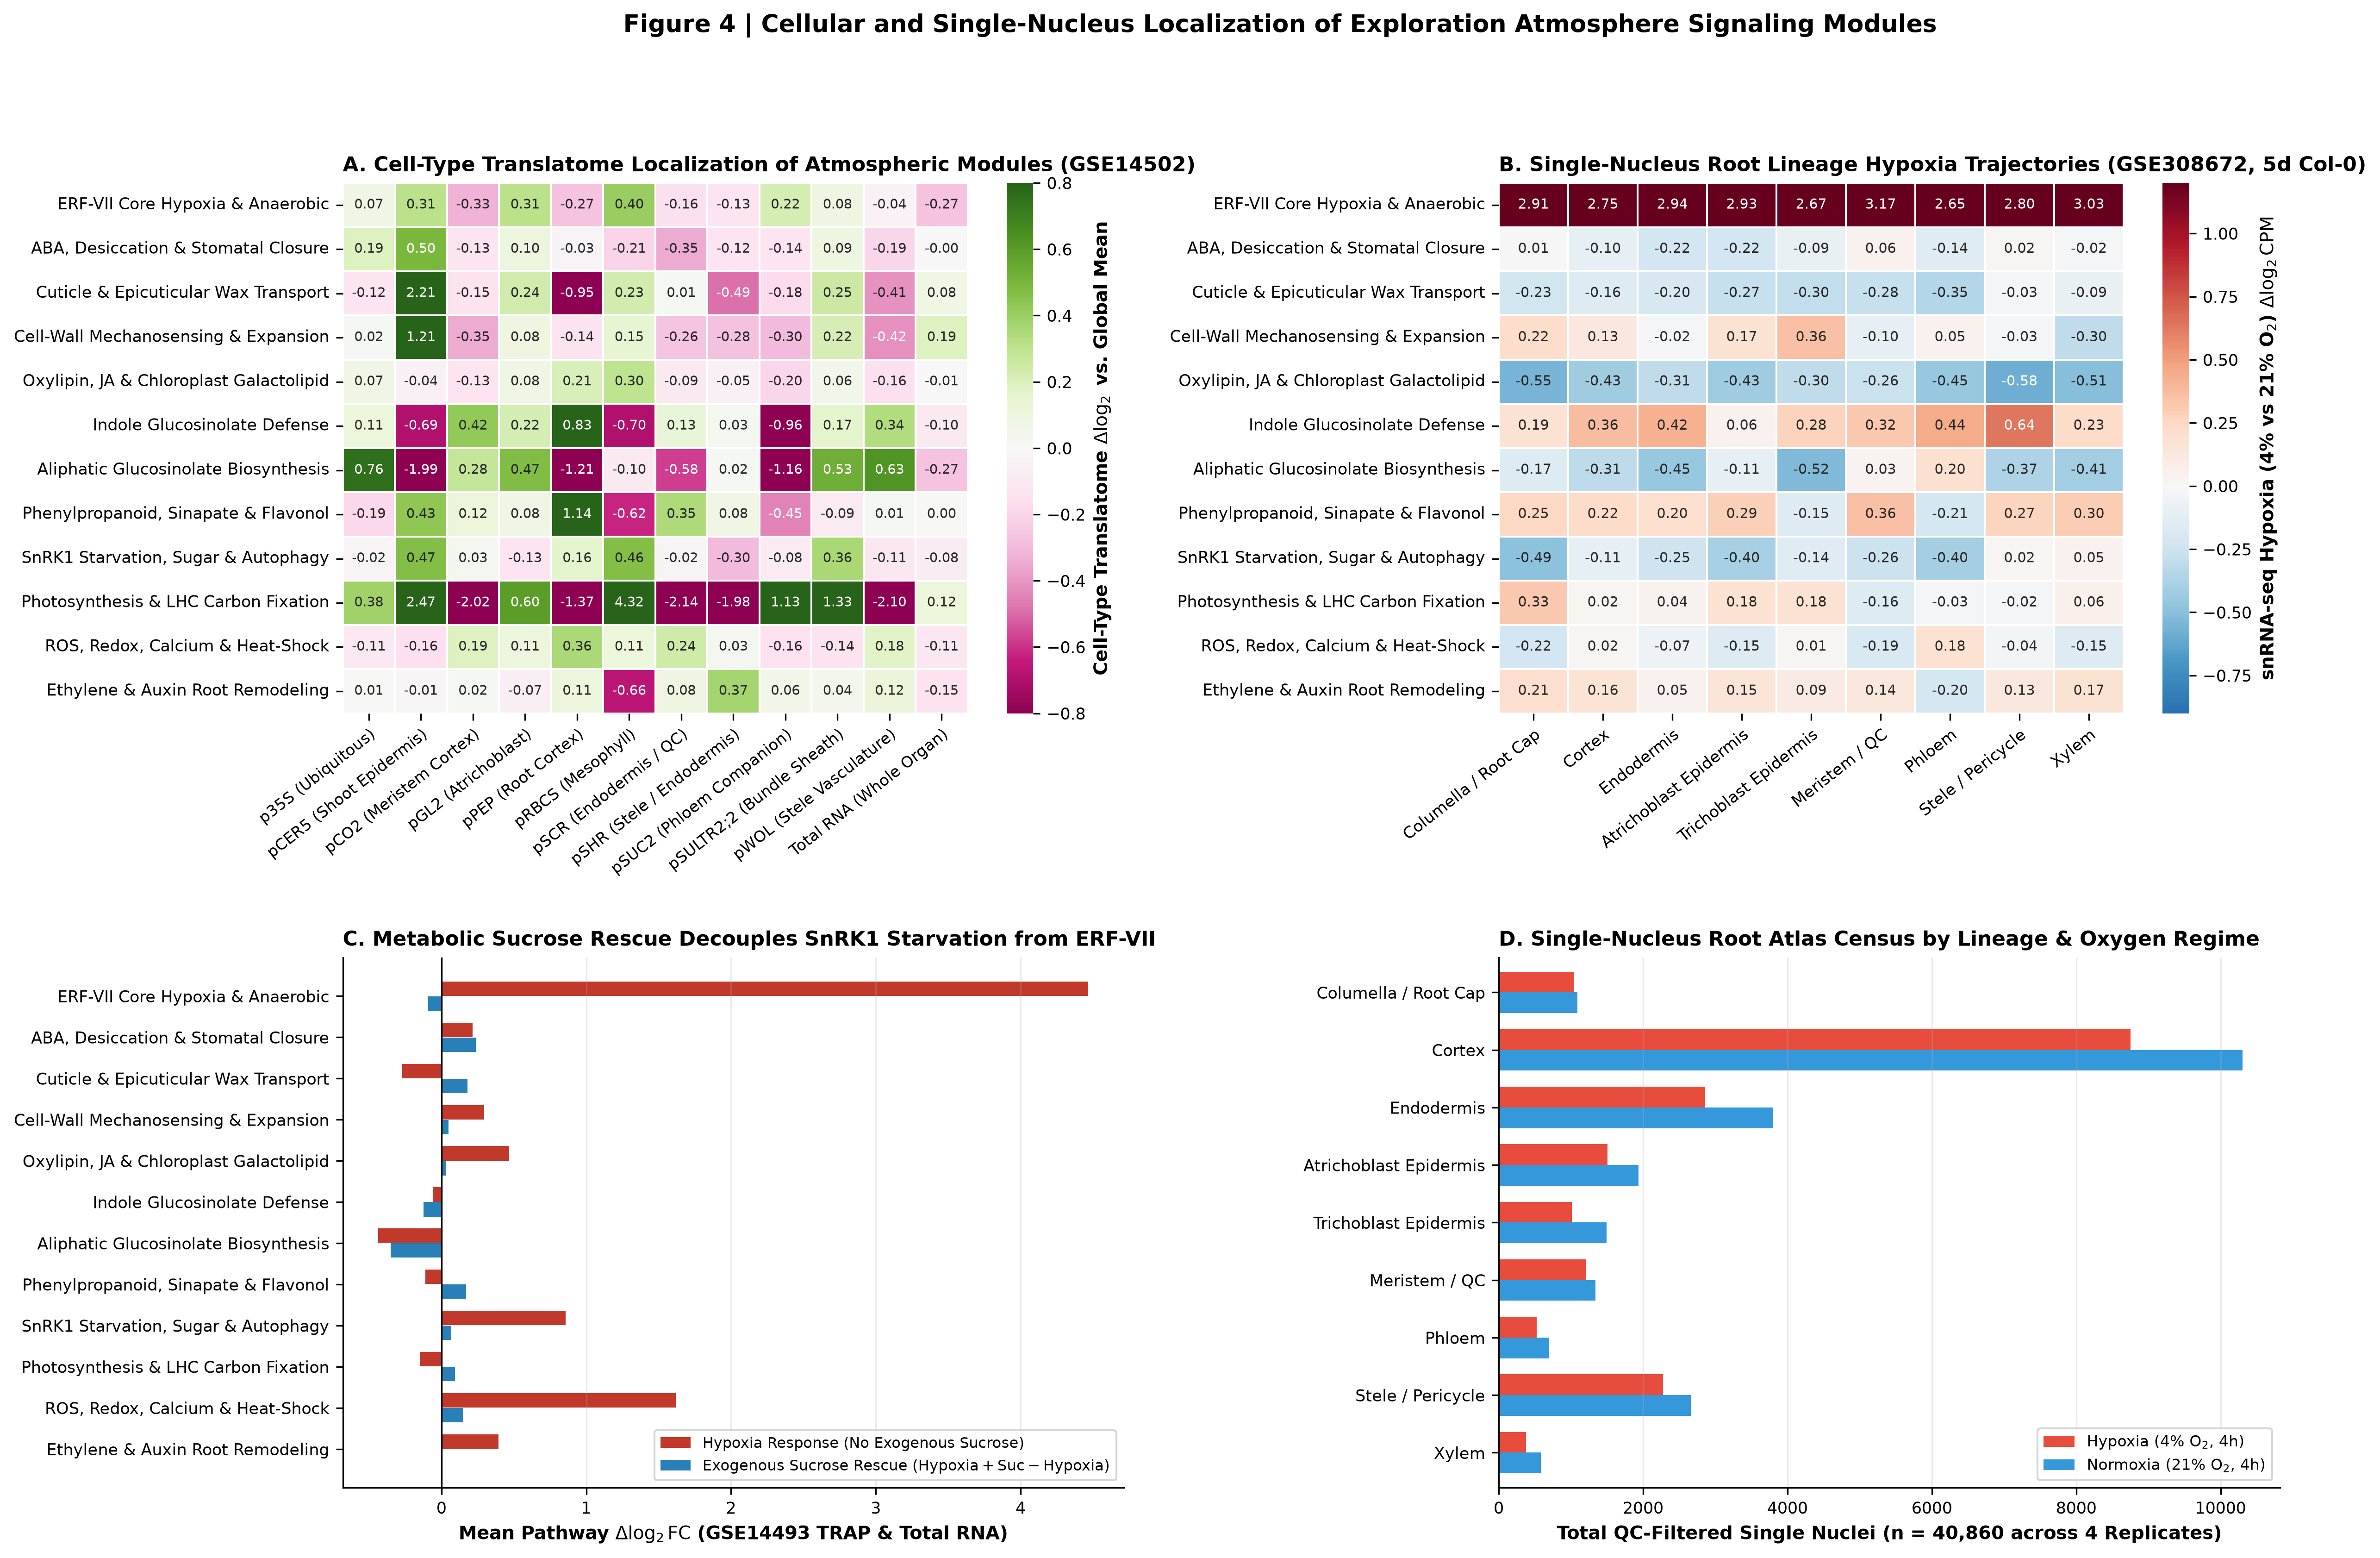

In [3]:
display(Image(filename=str(PROJECT_DIR / "manuscript/figures/fig4_cellular_tissue_localization.png")))

### Q&A
- **Are the $P_{\text{total}}$ barosensory hubs and $p\text{O}_2$ hypoxia hubs localized in the same cell types or spatially partitioned?** They are **spatially partitioned across distinct tissue layers**: cuticular lipid/wax barosensory hubs (`Cuticle_Epicuticular_Wax_Lipid_Transport`) and cell-wall mechanosensing hubs (`Cell_Wall_Mechanosensing_Expansion`) are strongly enriched in `pCER5` shoot epidermis (`+2.210` and `+1.209 log2` above baseline), photosynthetic/oxylipin hubs localize to `pRBCS` mesophyll (`+4.322` and `+0.296 log2`), and aliphatic/indole glucosinolate defense hubs localize to `pSULTR2;2` phloem companion/bundle sheath (`+0.529`), `pWOL` stele (`+0.628`), and `pPEP`/`pCO2` cortex (`+0.826` and `+0.423 log2`).
- **What does the 40,860-nucleus root tip hypoxia atlas (`GSE308672`) reveal about pure normobaric hypoxia vs. hypobaria?** Under pure normobaric 4% $\text{O}_2$, `ERF_VII_Core_Hypoxia_Anaerobic` is massively induced across all 9 root lineages (`+2.648` to `+3.174 log2CPM`, peaking in `Meristem_QC` `+3.174` and `Xylem` `+3.035`), whereas `ABA_Desiccation_Stomatal_Closure` (`-0.222` to `+0.057 log2CPM`) and `Cuticle_Epicuticular_Wax_Lipid_Transport` (`-0.347` to `-0.026 log2CPM`) remain completely uninduced.

### Data Analysis Key Findings
- Across the 40,860 QC-filtered root-tip nuclei in `GSE308672`, single-nucleus resolution proves that pure $\text{O}_2$ shortage activates ERF-VII anaerobic metabolism across all root layers (`+2.65` to `+3.17 log2CPM`) and indole glucosinolate defense in stele/pericycle (`+0.640 log2CPM`), but **never** triggers the ABA/desiccation or cuticular wax cascades seen in hypobaria.
- In `GSE14502` TRAP-seq, `ERF_VII_Core_Hypoxia_Anaerobic` polysomal loading increases by `+4.787` to `+5.216 log2` in root cortex (`pCO2`, `pPEP`) and `+4.602` to `+4.673 log2` in endodermis/stele (`pSCR`, `pSHR`, `pWOL`), whereas shoot mesophyll (`pRBCS`) exhibits a more muted `+2.685 log2` response.

### Insights or Next Steps
- Connect these epidermal/mesophyll barosensory modules directly to measured stomatal conductance, transpiration, $\delta^{13}\text{C}$, and LC-MS lipid/glucosinolate remodeling at $62\text{ kPa}$ vs $101\text{ kPa}$ in Notebook 04.